# Fluids (beta): Stokes flow

> **Beta.** `axionfem.fluids` is beta in this release. The solvers are checked against exact and manufactured solutions (see the last section), but their interfaces may still change. The module is compiled only in the MPI build.

Slow, viscous flow (Reynolds number $\mathrm{Re}\ll 1$) obeys the Stokes equations. This notebook sets up Stokes
problems through the `axionfem.fluids` Python API: a planar cavity and channel, a convergence study against an
analytic solution, and axisymmetric flows with swirl (a pipe, a translating sphere and a rotating sphere). It ends
with pointers to the tests and validation notes.

The solver uses Taylor–Hood elements: continuous quadratic velocity and continuous linear pressure (the pair
COMSOL calls P2+P1), assembled with MFEM and solved with a sparse direct solver. Two forms of the viscous term are
available:

$$
-\nabla\cdot\big(2\mu\,\boldsymbol\varepsilon(\mathbf u)\big)+\nabla p=\mathbf f
\quad(\texttt{form="stress"},\ \text{the default}),\qquad
-\nabla\cdot(\mu\nabla\mathbf u)+\nabla p=\mathbf f\quad(\texttt{form="laplacian"}),
$$

both with $\nabla\cdot\mathbf u=0$ and $\boldsymbol\varepsilon=\tfrac12(\nabla\mathbf u+\nabla\mathbf u^{T})$.
For constant $\mu$ and an incompressible flow the two are the same equation in the interior, so with the velocity
prescribed on the whole boundary they have the same solution. They differ in their natural boundary condition, i.e.
what "traction" means at an open boundary, and with an open boundary the two solutions differ near that boundary, over about one channel
width: only the outlet region of the long channel in section 1, but the whole of the short pipe in section 3. With variable $\mu$ only the stress form is the Newtonian viscous force:
$-\nabla\cdot(2\mu\boldsymbol\varepsilon)=-\nabla\cdot(\mu\nabla\mathbf u)-(\nabla\mathbf u)^{T}\nabla\mu$ for
$\nabla\cdot\mathbf u=0$. COMSOL's Creeping Flow interface uses the stress form.

**Units.** The API is kinematic, i.e. everything is per unit density: pass $\nu=\mu/\rho$ as the viscosity, body
forces per unit mass, and tractions, pressure drops and pressure-point values divided by $\rho$; multiply the
pressures and forces it returns by $\rho$. Stokes flow is linear, so this notebook works in units with
$\rho=\mu=1$.

**Requirements.** An MPI build of axionFEM (the fluids module is compiled only there; `import axionfem.fluids`
raises `ImportError` otherwise; see the [install guide](../docs/guides/install.md)), numpy and matplotlib.
Every cell runs in seconds on one core.

In [1]:
import math

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.tri import Triangulation, LinearTriInterpolator

import warnings
# show warnings without the temporary file name the kernel gives each cell
warnings.formatwarning = lambda message, category, *args, **kwargs: f"{category.__name__}: {message}\n"

import axionfem as af
from axionfem import fluids

print("axionFEM", af.__version__, "| sparse LU backends:",
      [b for b in ("eigen", "strumpack") if fluids.lu_backend_available(b)])
plt.rcParams.update({"figure.dpi": 80, "font.size": 10, "axes.grid": True, "grid.color": "#e4e3df",
                     "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
                     "lines.linewidth": 1.8, "legend.frameon": False})
BLUE, ORANGE, GREEN, GOLD, VIOLET, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#6f6e69"
LU = "eigen"        # Eigen's SparseLU: several times faster than STRUMPACK (the default when built) on these small meshes

# boundary attributes of every rectangle below
BOTTOM, RIGHT, TOP, LEFT = 1, 2, 3, 4


def rect_mesh(nx, ny, x0=0.0, x1=1.0, y0=0.0, y1=1.0):
    """Structured triangles on [x0, x1] x [y0, y1]; boundary attributes 1 bottom, 2 right, 3 top, 4 left.
    The two corner cells (bottom right, top left) are split along the other diagonal, so that no triangle has
    all three vertices on the boundary (such a triangle carries a spurious Taylor-Hood pressure mode)."""
    xs, ys = np.linspace(x0, x1, nx + 1), np.linspace(y0, y1, ny + 1)
    V = np.array([[x, y] for y in ys for x in xs])
    vid = lambda i, j: j * (nx + 1) + i
    tri = []
    for j in range(ny):
        for i in range(nx):
            a, b, c, d = vid(i, j), vid(i + 1, j), vid(i + 1, j + 1), vid(i, j + 1)
            flip = (i == nx - 1 and j == 0) or (i == 0 and j == ny - 1)
            tri += [[a, b, d], [b, c, d]] if flip else [[a, b, c], [a, c, d]]
    seg, att = [], []
    for i in range(nx):
        seg += [[vid(i, 0), vid(i + 1, 0)], [vid(i + 1, ny), vid(i, ny)]]
        att += [BOTTOM, TOP]
    for j in range(ny):
        seg += [[vid(nx, j), vid(nx, j + 1)], [vid(0, j + 1), vid(0, j)]]
        att += [RIGHT, LEFT]
    return fluids.Mesh.from_arrays(V, np.array(tri, np.int32), np.array(seg, np.int32), np.array(att, np.int32))


# a quadrature rule on the reference triangle (collapsed 7 x 7 Gauss, exact to degree 12) for error norms
_g, _w = np.polynomial.legendre.leggauss(7)
_s = 0.5 * (_g + 1)
QP = np.array([[a * (1 - b), b] for a in _s for b in _s])
QW = np.array([0.25 * wa * wb * (1 - b) for wa in _w for b, wb in zip(_s, _w)])


def at_quadrature(sol):
    """Points x, weights w (|det J| times the rule), u_h, grad u_h and p_h at the quadrature points of every element."""
    el = np.arange(sol.n_elements, dtype=np.int32)
    x, detJ = sol.geometry(el, QP)
    u, gu = sol.velocity(el, QP)
    return x, np.abs(detJ) * QW, u, gu, sol.pressure(el, QP)


def at_vertices(mesh, sol):
    """Triangulation of the mesh and the velocity at its vertices (for plots)."""
    V, E = mesh.vertices(), mesh.elements()
    u, _ = sol.velocity(np.arange(mesh.n_elements, dtype=np.int32), np.array([[0.0, 0.0], [1.0, 0.0], [0.0, 1.0]]))
    uv = np.zeros((len(V), u.shape[-1]))
    uv[E.ravel()] = u.reshape(-1, u.shape[-1])
    return Triangulation(V[:, 0], V[:, 1], E), uv


def solve(mesh, nu, force, bcs, **kw):
    """solve_stokes with the small-problem LU and vectorized callables; report the solver's own convergence gate."""
    sol = fluids.solve_stokes(mesh, nu, force, bcs, vectorized=True, lu=LU, **kw)
    d = sol.diagnostics
    assert d["converged"], f"not converged: relative residual {d['relative_residual']:.2e}"
    return sol

axionFEM 0.1.0 | sparse LU backends: ['eigen', 'strumpack']


## 1. Planar Stokes

### Meshes and boundary attributes

`fluids.Mesh.from_arrays(vertices, triangles, boundary_segments, boundary_attributes)` takes a triangle mesh from
any mesher as numpy arrays: vertex coordinates, counter-clockwise triangles, the boundary edges and an integer
attribute (≥ 1) per edge. Attributes play the role of COMSOL boundary selections: each boundary condition names
one. Here `rect_mesh` builds a structured mesh of a rectangle. `Mesh.taylor_hood_check()` lists triangles whose
three vertices all lie on the boundary (`tensor_all_boundary_vertices` is the same list for quadrilaterals); with
none, Boffi's sufficient condition for a stable P2/P1 pair holds on this mesh.

### Lid-driven cavity

A unit square with the top wall sliding. A lid speed that jumps from 1 to 0 at the corners makes the pressure
singular there, so the lid profile is regularized, $u_x=16x^2(1-x)^2$, which vanishes at both corners. Every wall is
a `"dirichlet"` boundary: the condition gives the velocity (a constant tuple, a callable, or omitted for no
slip).

In [2]:
cavity = rect_mesh(24, 24)
print("triangles:", cavity.n_elements, "| Taylor-Hood check:", cavity.taylor_hood_check())

lid = lambda X, Y: (16 * X**2 * (1 - X)**2, 0 * X)        # vectorized: arrays in, one array per component out
bcs = [{"attribute": TOP, "kind": "dirichlet", "value": lid}] + \
      [{"attribute": a, "kind": "dirichlet"} for a in (BOTTOM, RIGHT, LEFT)]   # no slip
cav = solve(cavity, 1.0, None, bcs)
d = cav.diagnostics
print(f"{d['dofs_velocity']} velocity + {d['dofs_pressure']} pressure DOFs, "
      f"relative residual {d['relative_residual']:.1e}, constant-pressure nullspace detected: {d['nullspace_detected']}")

triangles: 1152 | Taylor-Hood check: {'checked_elements': 1152, 'all_boundary_vertices': [], 'tensor_all_boundary_vertices': []}
4802 velocity + 625 pressure DOFs, relative residual 1.8e-15, constant-pressure nullspace detected: True


The diagnostics report the solver's own checks: `converged` (the relative residual of the assembled system is
below `direct_tol`, $10^{-10}$ by default) and the DOF counts. With velocity prescribed on the whole boundary, the
pressure is defined only up to a constant; the solver detects this (`nullspace_detected`) and returns the pressure
with zero mean. Pass `pressure_point={"x0": (x, y), "value": p0}` to fix it at a mesh vertex instead (COMSOL's
pressure point constraint).

The figure shows the speed and the streamlines. The primary vortex sits above the centre; the corner eddies at the
bottom are present but orders of magnitude weaker than the main flow and do not show at this scale.

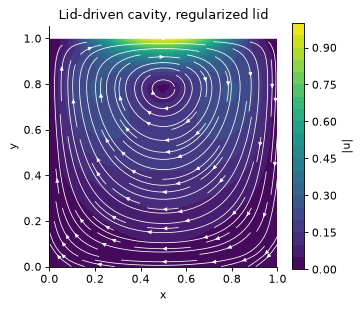

In [3]:
tri, uv = at_vertices(cavity, cav)
gx, gy = np.meshgrid(np.linspace(0, 1, 101), np.linspace(0, 1, 101))
ux = LinearTriInterpolator(tri, uv[:, 0])(gx, gy)
uy = LinearTriInterpolator(tri, uv[:, 1])(gx, gy)

fig, ax = plt.subplots(figsize=(4.6, 4))
cf = ax.tricontourf(tri, np.hypot(uv[:, 0], uv[:, 1]), 20, cmap="viridis")
ax.streamplot(gx, gy, ux.filled(0), uy.filled(0), color="w", density=1.2, linewidth=0.7, arrowsize=0.7)
fig.colorbar(cf, ax=ax, label="|u|")
ax.set(aspect="equal", xlabel="x", ylabel="y", title="Lid-driven cavity, regularized lid")
ax.grid(False)
plt.show()

### Boundary-condition kinds

Each boundary attribute takes exactly one condition, a dict `{"attribute": a, "kind": ..., ...}`:

| `kind` | condition | extra keys | COMSOL counterpart |
|---|---|---|---|
| `"dirichlet"` | $\mathbf u=\mathbf g$ | `value` (default 0) | Wall (no slip), Inlet (velocity) |
| `"do_nothing"` | $\boldsymbol\sigma_{\rm form}\,\mathbf n=0$ | | Outlet, $p_0=0$ |
| `"traction"` | $\boldsymbol\sigma_{\rm form}\,\mathbf n=\mathbf g$ | `value`; `normal_dependent=True` for $\mathbf g(x,y,n_x,n_y)$ | Boundary stress, Inlet/Outlet (pressure) |
| `"slip"`, `"symmetry"` | $\mathbf u\cdot\mathbf n=0$, zero tangential traction | optional `normal` | Slip wall, Symmetry |
| `"periodic"` | $\mathbf u(\mathbf x)=\mathbf u(\mathbf x+\mathbf d)$, with a pressure drop or a flow rate | `partner`, `translation` $=\mathbf d$, `pressure_drop` or `flow_rate` | Periodic flow condition |
| `"axis"` | $u_r=u_\theta=0$ on $r=0$ (axisymmetric only) | | Axial symmetry |

Here $\boldsymbol\sigma_{\rm form}$ is $-p\mathbf I+2\mu\boldsymbol\varepsilon$ in the stress form and
$-p\mathbf I+\mu\nabla\mathbf u$ in the Laplacian form; the "tangential traction" of `"slip"` is that of the chosen
form too. The COMSOL counterparts hold for the stress form (the Laplacian pseudo-traction has none, and COMSOL's
Outlet also suppresses backflow by default). A `"periodic"` condition is given once, on one side of the pair, and
names the opposite attribute as `partner`, with $\mathbf x_{\rm partner}=\mathbf x+\mathbf d$;
`pressure_drop` is $p(\mathbf x)-p(\mathbf x+\mathbf d)$, positive for flow towards the partner.

The next cell solves plane Poiseuille flow in the channel $0<x<4$, $0<y<1$ six ways. The exact solution for the
pressure gradient $\mathrm dp/\mathrm dx=-G$ is

$$
u_x=\frac{G}{2\mu}\,y(H-y),\qquad u_y=0,\qquad p=G(L-x).
$$

In [4]:
L, H, mu, G = 4.0, 1.0, 1.0, 1.0
pois = lambda X, Y: np.stack([G / (2 * mu) * Y * (H - Y), 0 * X], -1)
p_pois = lambda X, Y: G * (L - X)
channel = rect_mesh(8, 2, 0, L, 0, H)      # deliberately coarse: 2 cells across the channel
walls = [{"attribute": BOTTOM, "kind": "dirichlet"}, {"attribute": TOP, "kind": "dirichlet"}]
inlet = {"attribute": LEFT, "kind": "dirichlet", "value": pois}
outlet = {"attribute": RIGHT, "kind": "do_nothing"}
periodic = {"attribute": LEFT, "kind": "periodic", "partner": RIGHT, "translation": (L, 0.0)}
variants = {
    "velocity inlet, do-nothing outlet (laplacian)": (walls + [inlet, outlet], "laplacian"),
    "pressure inlet and outlet (laplacian)": (walls + [{"attribute": LEFT, "kind": "traction", "value": (G * L, 0.0)},
                                                      {"attribute": RIGHT, "kind": "traction", "value": (0.0, 0.0)}],
                                              "laplacian"),
    "periodic, pressure drop G L (stress)": (walls + [dict(periodic, pressure_drop=G * L)], "stress"),
    "periodic, flow rate G H^3/12 mu (stress)": (walls + [dict(periodic, flow_rate=G * H**3 / (12 * mu))], "stress"),
    "velocity on the whole boundary (stress)": ([{"attribute": a, "kind": "dirichlet", "value": pois}
                                                for a in (BOTTOM, RIGHT, TOP, LEFT)], "stress"),
    "velocity inlet, do-nothing outlet (stress)": (walls + [inlet, outlet], "stress"),
}
print(f"{'variant':46s} {'max|u-u_ex|':>12s} {'max|p-p_ex|':>12s}   pressure reference")
for name, (bc, form) in variants.items():
    s = solve(channel, mu, None, bc, form=form)
    x, w, u, gu, p = at_quadrature(s)
    du = np.max(np.abs(u - pois(x[..., 0], x[..., 1])))
    dp = p - p_pois(x[..., 0], x[..., 1])
    ref = "zero mean" if s.diagnostics["nullspace_detected"] else "set by the open boundary"
    if "periodic" in name:                             # p = periodic part - G_computed (x - x0): add the linear part back
        Gc = s.diagnostics["periodic_pressure_gradient"][0]
        dp = p - Gc * x[..., 0] - p_pois(x[..., 0], x[..., 1])
        dp = dp - np.sum(w * dp) / np.sum(w)
        ref = f"periodic part + linear part; computed gradient {Gc:.12f}"
    elif s.diagnostics["nullspace_detected"]:
        dp = dp - np.sum(w * dp) / np.sum(w)          # compare up to the constant
    print(f"{name:46s} {du:12.1e} {np.max(np.abs(dp)):12.1e}   {ref}")

variant                                         max|u-u_ex|  max|p-p_ex|   pressure reference
velocity inlet, do-nothing outlet (laplacian)       3.3e-16      5.3e-15   set by the open boundary
pressure inlet and outlet (laplacian)               2.8e-16      2.2e-15   set by the open boundary
periodic, pressure drop G L (stress)                5.1e-16      4.4e-15   periodic part + linear part; computed gradient 1.000000000000
periodic, flow rate G H^3/12 mu (stress)            3.1e-16      4.4e-15   periodic part + linear part; computed gradient 1.000000000000
velocity on the whole boundary (stress)             3.7e-16      5.1e-15   zero mean
velocity inlet, do-nothing outlet (stress)          1.1e-02      2.2e-01   set by the open boundary


The first five variants reproduce the exact solution to round-off on a mesh with two cells across the channel. The
parabola is in the quadratic velocity space and the linear pressure is in the pressure space, so the discrete
problem has the exact solution as its solution (a *patch test*). For the periodic variants the solver returns the
periodic part of the pressure (here a constant) and the mean gradient $G$ separately, in
`diagnostics["periodic_pressure_gradient"]`; with a prescribed flow rate, $G$ is the computed result. The full
pressure is the periodic part minus $G\,x$, up to a constant; the table compares it that way. Where the velocity is
prescribed on the whole boundary, the pressure is compared up to its mean.

The last row differs. In the stress form, the do-nothing outlet imposes
$\boldsymbol\sigma\mathbf n=(-p+2\mu\,\partial_x u_x,\ \mu(\partial_y u_x+\partial_x u_y))=0$, but developed
Poiseuille flow has the shear stress $\mu\,\partial_y u_x\neq0$ on any cross-section, so the outflow is distorted
near the outlet. In the Laplacian form the condition reads $(-p+\mu\,\partial_x u_x,\ \mu\,\partial_x u_y)=0$,
which developed flow satisfies with $p=0$. With constant viscosity, the Laplacian form is the convenient choice for
open inlets and outlets of straight channels (the usual "do-nothing" outflow) as long as every wall is at rest or in rigid
translation, with no slip. Use the stress form with variable viscosity, for rotating, deforming or slip walls, and wherever you need the
physical traction, e.g. a free surface or a prescribed shear.

### Force on a wall

`sol.reaction(attributes)` returns the force the fluid exerts on the given Dirichlet boundaries, computed from the
residual of the solved equations (the consistent, Babuška–Miller form, more accurate than differentiating
$\mathbf u_h$ at the wall). The residual is that of the form you solved. In the stress form this is the physical
force. In the Laplacian form the boundary flux is the pseudo-traction $(\mu\nabla\mathbf u-p\mathbf I)\mathbf n$,
which differs from $\boldsymbol\sigma\mathbf n$ by $\mu(\nabla\mathbf u)^T\mathbf n$: equal on a no-slip wall at
rest or in rigid translation, but not on a rotating, deforming or slip wall (section 3 shows a rotating sphere where it gives 2/3 of the
torque).

In the periodic channel, the pressure drop over one period is balanced by the shear on the two walls, so each wall
carries $\Delta p\,H/2=\tau_w L$, with $\tau_w=\mu\,\partial_y u_x|_{y=0}=GH/2$.

In [5]:
s = solve(channel, mu, None, walls + [dict(periodic, pressure_drop=G * L)], form="stress")
for wall in (BOTTOM, TOP):
    r = s.reaction([wall])
    print(f"wall {wall}: force on the wall (per unit depth) = ({r['force'][0]:.12f}, {r['force'][1]:.1e});"
          f"  expected (G L H / 2, 0) = ({G * L * H / 2}, 0)")

wall 1: force on the wall (per unit depth) = (2.000000000000, -5.8e-17);  expected (G L H / 2, 0) = (2.0, 0)
wall 3: force on the wall (per unit depth) = (2.000000000000, -8.3e-17);  expected (G L H / 2, 0) = (2.0, 0)


With a velocity (Dirichlet) inlet or outlet, the wall's corner node is shared with it, and the reaction there also
picks up part of the inlet's load: an $O(h)$ error, 17 % on this 8 × 2 channel (the wall force comes out
$1.667$ instead of $2$ in the Laplacian form, whose flow is exact here). Traction and pressure boundaries do not have this problem (the pipe below), and the
periodic channel has no corners at all.

## 2. Convergence against an analytic solution

Constant-viscosity Poiseuille flow is reproduced exactly, so it cannot show convergence. Let the viscosity vary
across the channel instead, as in a liquid layer with a temperature difference between its walls,
$\mu(y)=\mu_0\,e^{y/H}$. The flow is still unidirectional, $\mathbf u=(u(y),0)$, and the momentum balance
$\partial_y(\mu\,\partial_y u)=-G$ with $u(0)=u(H)=0$ integrates to

$$
u(y)=\frac{H}{\mu_0}\Big[C\,\big(1-e^{-\eta}\big)-GH\big(1-(1+\eta)\,e^{-\eta}\big)\Big],\qquad
\eta=\frac yH,\qquad C=GH\,\frac{e-2}{e-1}.
$$

This is not a polynomial, so the discrete solution converges to it. For Taylor–Hood P2/P1 the expected rates are
$\|\mathbf u-\mathbf u_h\|_{L^2}\propto h^3$ and $|\mathbf u-\mathbf u_h|_{H^1}\propto h^2$. The viscosity is passed
as a callable; with `vectorized=True` the solver tabulates it once at its quadrature points. Both forms give the
same flow here ($\mu$ depends only on $y$, and $u_y=0$); the stress form is used.

In [6]:
mu0 = 1.0
C = G * H * (math.e - 2) / (math.e - 1)
mu_y = lambda X, Y: mu0 * np.exp(Y / H)


def u_var(X, Y):
    eta = Y / H
    u = H / mu0 * (C * (1 - np.exp(-eta)) - G * H * (1 - (1 + eta) * np.exp(-eta)))
    return np.stack([u, 0 * u], -1)


def grad_u_var(X, Y):
    du = (C - G * Y) / mu_y(X, Y)                  # mu u' = C - G y
    z = 0 * X
    return np.stack([np.stack([z, du], -1), np.stack([z, z], -1)], -2)


def errors(sol, u_ex, grad_ex):
    """L2 norm of u - u_h and H1 seminorm of u - u_h, by quadrature."""
    x, w, u, gu, _ = at_quadrature(sol)
    X, Y = x[..., 0], x[..., 1]
    return (math.sqrt(np.sum(w * np.sum((u - u_ex(X, Y))**2, -1))),
            math.sqrt(np.sum(w * np.sum((gu - grad_ex(X, Y))**2, (-1, -2)))))


grad_pois = lambda X, Y: np.stack([np.stack([0 * X, G / (2 * mu) * (H - 2 * Y)], -1),
                                   np.stack([0 * X, 0 * X], -1)], -2)
Ls = 2.0                                           # one period of a shorter channel
rows = []
for n in (2, 4, 8, 16):
    m = rect_mesh(2 * n, n, 0, Ls, 0, H)
    bc = walls + [{"attribute": LEFT, "kind": "periodic", "partner": RIGHT, "translation": (Ls, 0.0),
                   "pressure_drop": G * Ls}]
    var = solve(m, mu_y, None, bc)
    const = solve(m, mu, None, bc)
    rows.append((H / n, *errors(var, u_var, grad_u_var), *errors(const, pois, grad_pois)))

h, eL2, eH1, cL2, cH1 = map(np.array, zip(*rows))
print(" h       L2 error   H1 error   | constant mu: L2, H1")
for r in rows:
    print(f" {r[0]:.4f}  {r[1]:.3e}  {r[2]:.3e}  | {r[3]:.1e}  {r[4]:.1e}")
print("observed orders, L2:", np.round(np.log2(eL2[:-1] / eL2[1:]), 2), " H1:", np.round(np.log2(eH1[:-1] / eH1[1:]), 2))

 h       L2 error   H1 error   | constant mu: L2, H1
 0.5000  1.360e-03  1.704e-02  | 1.4e-16  7.0e-16
 0.2500  1.735e-04  4.449e-03  | 3.8e-16  2.1e-15
 0.1250  2.180e-05  1.127e-03  | 1.6e-15  7.6e-15
 0.0625  2.729e-06  2.827e-04  | 5.2e-15  2.7e-14
observed orders, L2: [2.97 2.99 3.  ]  H1: [1.94 1.98 1.99]


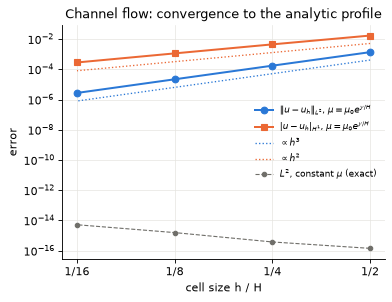

In [7]:
fig, ax = plt.subplots(figsize=(5.2, 3.8))
ax.loglog(h, eL2, "o-", color=BLUE, label=r"$\|u-u_h\|_{L^2}$, $\mu=\mu_0 e^{y/H}$")
ax.loglog(h, eH1, "s-", color=ORANGE, label=r"$|u-u_h|_{H^1}$, $\mu=\mu_0 e^{y/H}$")
ax.loglog(h, 0.3 * eL2[0] * (h / h[0])**3, ":", color=BLUE, lw=1.2, label=r"$\propto h^3$")
ax.loglog(h, 0.3 * eH1[0] * (h / h[0])**2, ":", color=ORANGE, lw=1.2, label=r"$\propto h^2$")
ax.loglog(h, np.maximum(cL2, 1e-17), "o--", color=GREY, ms=4, lw=1, label=r"$L^2$, constant $\mu$ (exact)")
ax.set(xlabel="cell size h / H", ylabel="error", title="Channel flow: convergence to the analytic profile")
ax.set_xticks(h, ["1/2", "1/4", "1/8", "1/16"])
ax.minorticks_off()
ax.legend(fontsize=8, loc="center right")
plt.show()

The errors fall by factors of 8 and 4 per halving of $h$, the Taylor–Hood rates. The grey line is the
constant-viscosity Poiseuille error on the same meshes: round-off at every level. A check like this on a problem
with a known solution, before trusting a new geometry, catches set-up mistakes such as a wrong attribute or a wrong
sign of a traction.

## 3. Axisymmetric Stokes with swirl

With `geometry="axisymmetric"` the mesh coordinates are $(r,z)$ (the mesh's $x$ is $r\ge0$, its $y$ is $z$) and the
velocity has three components $(u_r,u_z,u_\theta)$, all independent of $\theta$. The weak form carries the weight
$r$ and the hoop terms $u_r/r^2$, $u_\theta/r^2$; continuity is $\partial_r(r u_r)/r+\partial_z u_z=0$. The swirl
$u_\theta$ is decoupled from the meridional flow $(u_r,u_z)$ in Stokes flow, but both are solved together.

Velocity data, body forces and tractions are three-component tuples of $(r,z,\theta)$ components. The symmetry axis $r=0$
takes the `"axis"` condition: $u_r=u_\theta=0$ there, imposed at every velocity node (COMSOL's Axial symmetry).
`reaction` returns full 3D values (integrated over $2\pi$) in Cartesian components: `["force"]` is $(0,0,F_z)$, so the
axial force is index 2 (not index 1 as in the velocity data), and `["torque"]` is the torque about the axis.

### Hagen–Poiseuille pipe

A pipe of radius $R=1$ and length $L=2$, driven by the pressure difference $\Delta p=GL$ between its ends. The
exact solution is $u_z=\frac{G}{4\mu}(R^2-r^2)$, flow rate $Q=\pi GR^4/(8\mu)$, and the wall carries the axial
force $\Delta p\,\pi R^2$. The ends are `"traction"` boundaries with pure pressure,
$\boldsymbol\sigma\mathbf n=-p\,\mathbf n$: $(0,\Delta p,0)$ at the inlet $z=0$ (outward normal $-\mathbf e_z$) and
zero at the outlet.

In [8]:
Rp, Lp, Gp = 1.0, 2.0, 1.0
pipe = rect_mesh(4, 8, 0, Rp, 0, Lp)                  # x = r, y = z; LEFT is the axis r = 0
AXIS_P, WALL_P, INLET_P, OUTLET_P = LEFT, RIGHT, BOTTOM, TOP
u_hp = lambda R, Z: np.stack([0 * R, Gp / (4 * mu) * (Rp**2 - R**2), 0 * R], -1)
pipe_bcs = [{"attribute": AXIS_P, "kind": "axis"}, {"attribute": WALL_P, "kind": "dirichlet"},
            {"attribute": INLET_P, "kind": "traction", "value": (0.0, Gp * Lp, 0.0)},
            {"attribute": OUTLET_P, "kind": "traction", "value": (0.0, 0.0, 0.0)}]
Q_exact = math.pi * Gp * Rp**4 / (8 * mu)
pipes = {}
for form in ("laplacian", "stress"):
    s = solve(pipe, mu, None, pipe_bcs, form=form, geometry="axisymmetric")
    x, w, u, gu, p = at_quadrature(s)
    r = x[..., 0]
    Q = 2 * math.pi * np.sum(w * r * u[..., 1]) / Lp       # (1/L) * volume integral of u_z = flow rate
    F = s.reaction([WALL_P])["force"][2]
    err = np.max(np.abs(u - u_hp(r, x[..., 1])), axis=(0, 1))       # per component (u_r, u_z, u_theta)
    pipes[form] = s
    print(f"{form:9s}: max|u_z - exact| = {err[1]:.1e}, max|u_r| = {err[0]:.1e}   Q = {Q:.6f} (exact {Q_exact:.6f})   "
          f"wall force = {F:.6f} (Δp π R² = {Gp * Lp * math.pi * Rp**2:.6f})")

laplacian: max|u_z - exact| = 1.0e-15, max|u_r| = 1.1e-16   Q = 0.392699 (exact 0.392699)   wall force = 6.283185 (Δp π R² = 6.283185)
stress   : max|u_z - exact| = 3.3e-02, max|u_r| = 4.2e-02   Q = 0.423631 (exact 0.392699)   wall force = 6.283185 (Δp π R² = 6.283185)


The Laplacian form reproduces the exact pipe flow on 64 triangles (4 × 8 cells). The stress form with the same
pure-pressure ends gives a flow rate about 8 % too high (8.7 % on fine meshes): its traction includes the viscous
shear $\mu\,\partial_r u_z$, which developed pipe flow carries on every cross-section, and prescribing it as zero
changes the flow (the same effect as the planar outlet above). The shear-free ends also let the fluid move
radially there: $u_r$ reaches about 17 % of the centreline speed on the end planes. In this short pipe, two radii
long, the whole flow is affected; the axial deviation is largest near the axis close to the ends. The wall force
equals $\Delta p\,\pi R^2$ in both forms, but that holds for any discrete solution (the reaction balances the
applied end loads by construction), so it says nothing about the accuracy of the flow. The markers below are the
computed values at the quadratic element's nodes on two cross-sections.

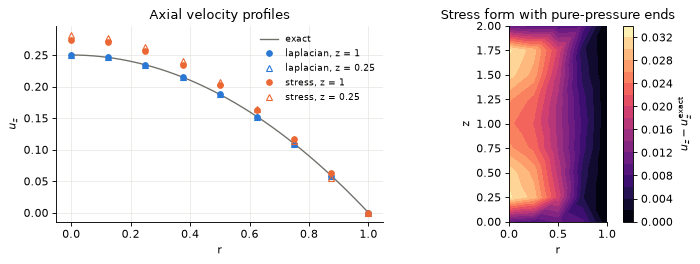

In [9]:
P2_NODES = np.array([[0, 0], [1, 0], [0, 1], [0.5, 0], [0.5, 0.5], [0, 0.5]], float)


def nodal_values(sol):
    """Coordinates and velocity at the 6 nodes of every quadratic element (vertices and edge midpoints)."""
    el = np.arange(sol.n_elements, dtype=np.int32)
    x, _ = sol.geometry(el, P2_NODES)
    u, _ = sol.velocity(el, P2_NODES)
    return x.reshape(-1, 2), u.reshape(-1, u.shape[-1])


fig, axs = plt.subplots(1, 2, figsize=(9, 3.4))
rr = np.linspace(0, Rp, 41)
axs[0].plot(rr, u_hp(rr, 0 * rr)[:, 1], "-", color=GREY, lw=1.2, label="exact")
for form, col in (("laplacian", BLUE), ("stress", ORANGE)):
    xn, un = nodal_values(pipes[form])
    for zc, mk in ((Lp / 2, "o"), (Lp / 8, "^")):
        on = np.abs(xn[:, 1] - zc) < 1e-12
        r_on, i = np.unique(xn[on, 0], return_index=True)
        axs[0].plot(r_on, un[on, 1][i], mk, color=col, ms=5, mfc="none" if mk == "^" else col,
                    label=f"{form}, z = {zc:g}")
axs[0].set(xlabel="r", ylabel="$u_z$", title="Axial velocity profiles")
axs[0].legend(fontsize=8)
tri, uv = at_vertices(pipe, pipes["stress"])
cf = axs[1].tricontourf(tri, uv[:, 1] - u_hp(tri.x, tri.y)[:, 1], 20, cmap="magma")    # >= 0 everywhere
fig.colorbar(cf, ax=axs[1], label=r"$u_z-u_z^{\rm exact}$")
axs[1].set(aspect="equal", xlabel="r", ylabel="z", title="Stress form with pure-pressure ends")
axs[1].grid(False)
plt.tight_layout()
plt.show()

### Stokes drag and torque on a sphere

A sphere of radius $a$ in a uniform stream $U\mathbf e_z$ feels the Stokes drag $F=6\pi\mu aU$. The exact
(Stokes 1851) solution in spherical coordinates $(\rho,\vartheta)$ around the sphere is

$$
u_\rho=U\cos\vartheta\Big(1-\frac{3a}{2\rho}+\frac{a^3}{2\rho^3}\Big),\qquad
u_\vartheta=-U\sin\vartheta\Big(1-\frac{3a}{4\rho}-\frac{a^3}{4\rho^3}\Big),\qquad
p=-\frac{3\mu U a\cos\vartheta}{2\rho^2}.
$$

The domain is the shell $a<\rho<4a$ in the meridional half-plane: no slip on the sphere, the axis above and below
it, and the exact solution as Dirichlet data on the outer sphere $\rho=4a$, so that truncating the domain changes
nothing. The same mesh gives the rotating sphere, a pure swirl problem: a sphere spinning at $\Omega$ about $z$ in
fluid at rest drives $u_\theta=\Omega a^3 r/\rho^3$ and feels the torque $-8\pi\mu a^3\Omega$.

The curved boundaries matter. With straight-sided triangles the computed drag is that of a polygonal body, and
converges at only second order. `Mesh.from_arrays(..., p2_nodes=X6)` takes six geometry nodes per triangle
(vertices, then edge midpoints); here the edge midpoints on the two circles are placed on the circles, giving
isoparametric quadratic elements (COMSOL's default curved-element geometry order for P2).

In [10]:
AXIS_S, SPHERE, OUTER = 1, 2, 3
a_s, R_out, U, Omega = 1.0, 4.0, 1.0, 1.0


def sphere_mesh(n_rho, n_th):
    """Mapped mesh of a <= rho <= R_out, 0 <= theta <= pi with rho = a (R_out/a)^s (cells grow with rho), theta = pi t.
    Attributes: AXIS_S (r = 0, above and below), SPHERE, OUTER; edge midpoints on both circles lie on the circles."""
    S, T = (A.ravel() for A in np.meshgrid(np.linspace(0, 1, n_rho + 1), np.linspace(0, 1, n_th + 1)))
    rho, th = a_s * (R_out / a_s)**S, np.pi * T
    V = np.c_[rho * np.sin(th), rho * np.cos(th)]
    V[(T == 0) | (T == 1), 0] = 0.0                               # exactly on the axis
    vid = lambda i, j: j * (n_rho + 1) + i
    tri = []
    for j in range(n_th):
        for i in range(n_rho):
            a, b, c, d = vid(i, j), vid(i + 1, j), vid(i + 1, j + 1), vid(i, j + 1)
            flip = (i == n_rho - 1 and j == 0) or (i == 0 and j == n_th - 1)   # as in rect_mesh
            tri += [[a, d, b], [b, d, c]] if flip else [[a, c, b], [a, d, c]]  # counter-clockwise in (r, z)
    tri = np.array(tri, np.int32)
    seg = [[vid(i, 0), vid(i + 1, 0)] for i in range(n_rho)] + [[vid(i, n_th), vid(i + 1, n_th)] for i in range(n_rho)] \
        + [[vid(0, j), vid(0, j + 1)] for j in range(n_th)] + [[vid(n_rho, j), vid(n_rho, j + 1)] for j in range(n_th)]
    att = [AXIS_S] * (2 * n_rho) + [SPHERE] * n_th + [OUTER] * n_th
    X6 = np.empty((len(tri), 6, 2))
    X6[:, :3] = V[tri]
    rad = np.hypot(V[:, 0], V[:, 1])
    for k, (i, j) in enumerate(((0, 1), (1, 2), (2, 0))):
        A, B = V[tri[:, i]], V[tri[:, j]]
        mid = 0.5 * (A + B)
        for Rc in (a_s, R_out):                                    # an edge on a circle: midpoint onto the circle
            on = (np.abs(rad[tri[:, i]] - Rc) < 1e-12) & (np.abs(rad[tri[:, j]] - Rc) < 1e-12)
            mid[on] *= Rc / np.hypot(mid[on, 0], mid[on, 1])[:, None]
        X6[:, 3 + k] = mid
    return fluids.Mesh.from_arrays(V, tri, np.array(seg, np.int32), np.array(att, np.int32), p2_nodes=X6)


def stokes_stream(R, Z):
    """Exact Stokes flow past the fixed sphere, as (u_r, u_z, u_theta)."""
    rho = np.hypot(R, Z)
    c, s = Z / rho, R / rho
    u_rho = U * c * (1 - 1.5 * a_s / rho + 0.5 * a_s**3 / rho**3)
    u_th = -U * s * (1 - 0.75 * a_s / rho - 0.25 * a_s**3 / rho**3)
    return np.stack([u_rho * s + u_th * c, u_rho * c - u_th * s, 0 * R], -1)


def rotlet(R, Z):
    """Exact flow around the sphere rotating at Omega: pure swirl."""
    return np.stack([0 * R, 0 * R, Omega * a_s**3 * R / np.hypot(R, Z)**3], -1)


spin = lambda R, Z: np.stack([0 * R, 0 * R, Omega * R], -1)       # rigid rotation on the sphere
F_exact, T_exact = 6 * math.pi * mu * a_s * U, -8 * math.pi * mu * a_s**3 * Omega
sph = []
for k in range(4):
    m = sphere_mesh(2 * 2**k, 4 * 2**k)
    tr = solve(m, mu, None, [{"attribute": AXIS_S, "kind": "axis"}, {"attribute": SPHERE, "kind": "dirichlet"},
                             {"attribute": OUTER, "kind": "dirichlet", "value": stokes_stream}], geometry="axisymmetric")
    ro = solve(m, mu, None, [{"attribute": AXIS_S, "kind": "axis"},
                             {"attribute": SPHERE, "kind": "dirichlet", "value": spin},
                             {"attribute": OUTER, "kind": "dirichlet", "value": rotlet}], geometry="axisymmetric")
    F, Tq = tr.reaction([SPHERE])["force"][2], ro.reaction([SPHERE])["torque"]
    sph.append((k, m.n_elements, F, Tq))
    if k == 0:
        print("Taylor-Hood check of the level-0 mesh:", m.taylor_hood_check())
    print(f"level {k}: {m.n_elements:5d} triangles  drag F_z = {F:.8f}  (6πμaU = {F_exact:.8f}, rel. error "
          f"{abs(F / F_exact - 1):.1e})   torque = {Tq:.8f}  (rel. error {abs(Tq / T_exact - 1):.1e})")
sph_mesh, sph_sol = m, tr

Taylor-Hood check of the level-0 mesh: {'checked_elements': 16, 'all_boundary_vertices': [], 'tensor_all_boundary_vertices': []}
level 0:    16 triangles  drag F_z = 20.23045746  (6πμaU = 18.84955592, rel. error 7.3e-02)   torque = -26.12146128  (rel. error 3.9e-02)
level 1:    64 triangles  drag F_z = 18.98161022  (6πμaU = 18.84955592, rel. error 7.0e-03)   torque = -25.20446170  (rel. error 2.9e-03)
level 2:   256 triangles  drag F_z = 18.85951773  (6πμaU = 18.84955592, rel. error 5.3e-04)   torque = -25.13774649  (rel. error 2.0e-04)
level 3:  1024 triangles  drag F_z = 18.85023495  (6πμaU = 18.84955592, rel. error 3.6e-05)   torque = -25.13307258  (rel. error 1.3e-05)


observed orders per halving of h: drag [3.39 3.73 3.87]  torque [3.79 3.84 3.92]


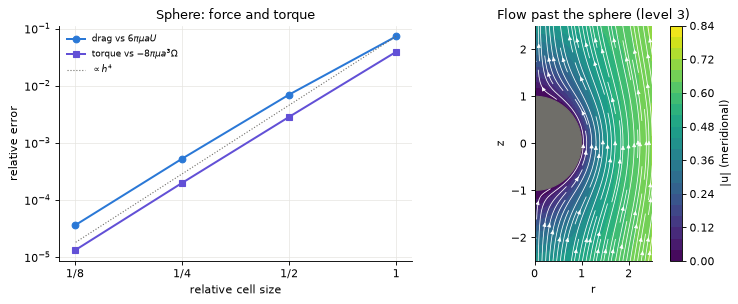

In [11]:
ks = np.array([r[0] for r in sph])
eF = np.array([abs(r[2] / F_exact - 1) for r in sph])
eT = np.array([abs(r[3] / T_exact - 1) for r in sph])
print("observed orders per halving of h: drag", np.round(np.log2(eF[:-1] / eF[1:]), 2),
      " torque", np.round(np.log2(eT[:-1] / eT[1:]), 2))

fig, axs = plt.subplots(1, 2, figsize=(9.5, 3.9))
hs = 2.0**-ks
axs[0].loglog(hs, eF, "o-", color=BLUE, label=r"drag vs $6\pi\mu aU$")
axs[0].loglog(hs, eT, "s-", color=VIOLET, label=r"torque vs $-8\pi\mu a^3\Omega$")
axs[0].loglog(hs, eF[0] * hs**4, ":", color=GREY, lw=1, label=r"$\propto h^4$")
axs[0].set(xlabel="relative cell size", ylabel="relative error", title="Sphere: force and torque")
axs[0].set_xticks(hs, ["1", "1/2", "1/4", "1/8"])
axs[0].minorticks_off()
axs[0].legend(fontsize=8)

tri, uv = at_vertices(sph_mesh, sph_sol)
gr, gz = np.meshgrid(np.linspace(0, 2.5, 101), np.linspace(-2.5, 2.5, 201))
inside = np.hypot(gr, gz) < a_s
ur = np.ma.masked_where(inside, LinearTriInterpolator(tri, uv[:, 0])(gr, gz).filled(0))
uz = np.ma.masked_where(inside, LinearTriInterpolator(tri, uv[:, 1])(gr, gz).filled(0))
cf = axs[1].tricontourf(tri, np.hypot(uv[:, 0], uv[:, 1]), 20, cmap="viridis")
axs[1].streamplot(gr, gz, ur, uz, color="w", density=1.1, linewidth=0.7, arrowsize=0.7)
axs[1].add_patch(plt.Circle((0, 0), a_s, color=GREY))
fig.colorbar(cf, ax=axs[1], label="|u| (meridional)")
axs[1].set(aspect="equal", xlim=(0, 2.5), ylim=(-2.5, 2.5), xlabel="r", ylabel="z", title="Flow past the sphere (level 3)")
axs[1].grid(False)
plt.tight_layout()
plt.show()

Drag and torque converge to the analytic values at close to fourth order: the reaction is a functional of the
solution and converges at twice the $H^1$ rate. The finest level, with about a thousand triangles, reaches a
relative error of $4\times10^{-5}$ against $6\pi\mu aU$.

The next cell solves the rotating sphere again in the Laplacian form. The flow is the same (all-Dirichlet data), but
the default `reaction` uses the Laplacian residual and returns the pseudo-traction torque, two thirds of the true
value at every mesh level; `residual_form="stress"` evaluates the residual of the stress form instead. That is exact here only because
for pure swirl both forms give the same discrete solution; for a general flow it is a diagnostic, and the remedy is
to solve in the stress form.

In [12]:
for k in (1, 2):
    m = sphere_mesh(2 * 2**k, 4 * 2**k)
    ro_lap = solve(m, mu, None, [{"attribute": AXIS_S, "kind": "axis"},
                                 {"attribute": SPHERE, "kind": "dirichlet", "value": spin},
                                 {"attribute": OUTER, "kind": "dirichlet", "value": rotlet}],
                   geometry="axisymmetric", form="laplacian")
    t_default = ro_lap.reaction([SPHERE])["torque"]
    t_stress = ro_lap.reaction([SPHERE], residual_form="stress")["torque"]
    print(f"level {k}, laplacian form: torque / (-8πμa³Ω) = {t_default / T_exact:.4f} (default reaction), "
          f"{t_stress / T_exact:.6f} (residual_form='stress')")

level 1, laplacian form: torque / (-8πμa³Ω) = 1.0029 (default reaction), 1.002854 (residual_form='stress')
level 2, laplacian form: torque / (-8πμa³Ω) = 1.0002 (default reaction), 1.000199 (residual_form='stress')


### Why the outer boundary matters

The exact far field on $\rho=4a$ hides the cost of truncating the domain. The next cell instead prescribes the
uniform stream $U\mathbf e_z$ on $\rho=4a$, as one would without an analytic solution. This is a sphere at the
centre of a spherical container of radius $b=4a$, which has the closed form (Cunningham 1910; see Happel and
Brenner, *Low Reynolds Number Hydrodynamics*)

$$
\frac{F}{6\pi\mu aU}=\frac{1-\lambda^5}{1-\tfrac94\lambda+\tfrac52\lambda^3-\tfrac94\lambda^5+\lambda^6},
\qquad\lambda=\frac ab .
$$

In [13]:
lam = a_s / R_out
K = (1 - lam**5) / (1 - 2.25 * lam + 2.5 * lam**3 - 2.25 * lam**5 + lam**6)
for k in (2, 3):
    m = sphere_mesh(2 * 2**k, 4 * 2**k)
    s = solve(m, mu, None, [{"attribute": AXIS_S, "kind": "axis"}, {"attribute": SPHERE, "kind": "dirichlet"},
                            {"attribute": OUTER, "kind": "dirichlet", "value": (0.0, U, 0.0)}], geometry="axisymmetric")
    Fc = s.reaction([SPHERE])["force"][2]
    print(f"level {k}: F / 6πμaU = {Fc / F_exact:.6f}   closed form {K:.6f}   (rel. difference {abs(Fc / F_exact / K - 1):.1e})")

level 2: F / 6πμaU = 2.106008   closed form 2.104938   (rel. difference 5.1e-04)
level 3: F / 6πμaU = 2.105011   closed form 2.104938   (rel. difference 3.5e-05)


A container four sphere radii out more than doubles the drag. Stokes flow decays only as $1/\rho$, so a uniform
velocity on a truncated outer boundary acts as a nearby wall; the correction falls off only as $\lambda=a/b$ for
large containers. For a sphere in a cylindrical tube, as in a falling-ball viscometer, the analogous wall
correction is tabulated in the literature (Haberman and Sayre 1958).

## 4. Tests and validation

The Stokes solvers of this notebook are exercised by the API tests `tests/test_fluids_api.py` (exact Poiseuille flow, explicit boundary conditions, the pressure point, the Couette torque), `tests/test_fluids_stokes_planar_api.py` (planar), `tests/test_fluids_stokes_axi_api.py` (axisymmetric with swirl) and `tests/test_fluids_stokes_3d_api.py` (3D): patch tests for polynomial solutions, force and torque reactions, boundary-condition kinds, periodic pairs and the refusal of unstable element pairs. The other solvers of `axionfem.fluids` have their own API tests: `tests/test_fluids_navier_stokes_api.py` (steady Navier-Stokes), `tests/test_fluids_transient_api.py` (transient Navier-Stokes), `tests/test_fluids_transport_api.py` (scalar transport and Boussinesq natural convection), `tests/test_fluids_gls_api.py` (stabilized equal-order P1/P1 elements) and `tests/test_fluids_mhd_api.py` (inductionless MHD).

The verification cases, with their acceptance criteria and reference numbers, are in `benchmarks/fluids/` (see its README), together with a small runner that executes the cases and checks the criteria (`python benchmarks/fluids/run.py --help`). They check convergence orders against manufactured solutions, agreement with closed-form solutions (such as the Poiseuille and Stokes-sphere solutions above), conservation identities, and agreement with other codes. No current case compares with a published numerical or measured value (the `literature` level of a case). The cross-code reference generators for NGSolve and FEniCSx (`tools/fluids_mms/`) are optional scripts that are not needed to run the tests. The [fluids guide](../docs/guides/fluids.md) describes the formulations and their limitations.

Hand-built meshes need a Taylor-Hood check (`Mesh.taylor_hood_check()`) and a comparison with a known solution before a new geometry is trusted; the convergence studies above are a template for that.